# 2. Boulware or Conceder: conceding with the clock

Examples of:

- the **time-dependent** strategies: the offer only depends on the time left;
- what **Boulware** and **Conceder** agents are, and which one wins;
- why conceding late becomes dangerous when the negotiation may **break down**.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from carpool import *

---

## 2.1 The formula

$$p(t) = p_0 + (s - p_0)\; t^{1/\beta} \qquad t = \frac{r}{T-1} \in [0, 1]$$

- $p_0$: the first offer, $s$: the limit (never crossed);
- $t = 0$ at the first round, $t = 1$ at the last round: the agent offers its limit;
- $\beta$ sets **when** the agent concedes: $\beta < 1$ **Boulware** (late), $\beta = 1$ linear, $\beta > 1$ **Conceder** (early).

**Exercise 1**.  
Write a function `offer(t, start, limit, beta)` that applies the formula.  
Plot Alice's offer ($p_0 = 18$, $s = 4$) for $t$ from 0 to 1 and $\beta = 0.3$, $1$ and $3$.  
What does Alice ask at mid-time ($t = 0.5$) in each case?

In [2]:
# Exercise 1: your code here

Boulware : at t = 0.5 Alice asks 16.6 EUR
linear   : at t = 0.5 Alice asks 11.0 EUR
Conceder : at t = 0.5 Alice asks 6.9 EUR


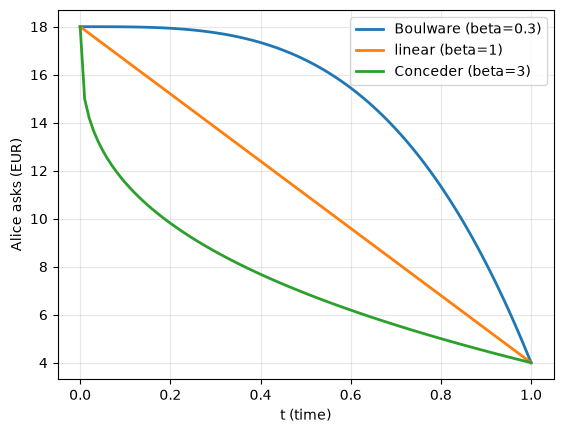

In [ ]:


t = np.linspace(0, 1, 101)
for beta, name in ((0.3, "Boulware"), (1, "linear"), (3, "Conceder")):
    plt.plot(t, offer(t, 18, 4, beta), lw=2, label=f"{name} (beta={beta})")
    print(f"{name:9s}: at t = 0.5 Alice asks {offer(0.5, 18, 4, beta):.1f} EUR")
plt.xlabel("t (time)"); plt.ylabel("Alice asks (EUR)"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Reading.**   
At mid-time, the Boulware Alice still asks 16.6 EUR, the linear one 11 EUR, the Conceder only 6.9 EUR.  
The Boulware agent stays firm and concedes at the last moment; the Conceder gives a lot at once, then hardly moves.

The name comes from Lemuel Boulware (General Electric, 1950s), known for making one firm offer and **not moving**.

---

## 2.2 Who wins?

`carpool.py` contains the same formula as a strategy: `time_dependent(r, T, start, limit, beta)`.  
`negotiate(alice_strategy, bob_strategy, T=T, risk=0.0, seed=None, tol=0.5)` runs a negotiation between two strategies.  
It returns `dict: price (None if no deal), round of the deal, offers of Alice and of Bob, gains`.  
`risk` is the probability that the negotiation stops before each new round (Bob takes the train...).  
`T` is the maximum number of rounds.  
`tol` is the tolerance to compare the gains of Alice and Bob.

A Boulware Alice is written:

{'price': 15.303192659626955, 'round': 6, 'alice': [18.0, 17.990767492462595, 17.906942155282486, 17.640479339225596, 17.062035700660463, 16.026579272940868, 14.376258812945725], 'bob': [4.0, 10.730497994767905, 12.479896099883318, 13.707057840908885, 14.68399959716443, 15.508989680208861, 16.230126506308185], 'gains': (11.303192659626955, 2.696807340373045)}


<Axes: title={'center': 'deal at 15.30 EUR (round 6)'}, xlabel='round', ylabel='price (EUR)'>

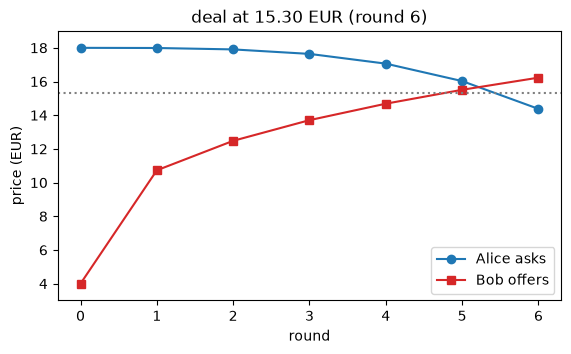

In [3]:
alice_boulware = lambda r, T, mine, theirs: time_dependent(r, T, start=18, limit=4, beta=0.3)
bob_conceder = lambda r, T, mine, theirs: time_dependent(r, T, start=4, limit=18, beta=3)
nego = negotiate(alice_boulware, bob_conceder)
print(nego)
show(nego)

**Exercise 2**.   
Make Alice and Bob negotiate for the four pairs: 
  - linear/linear, 
  - Boulware/Conceder, 
  - Conceder/Boulware, 
  - Boulware/Boulware ($\beta = 0.3$ for Boulware, $3$ for Conceder). 

Define Alice and Bob strategies with `time_dependent`, print the price, the round and the gains.

In [5]:
# Exercise 2: your code here

In [ ]:
def alice(beta): 
    //TODO: complete the strategy
def bob(beta):
    //TODO: complete the strategy

//TODO: complete the function


Alice beta=  1, Bob beta=  1: price 11.00 EUR at round 5, gains [7. 7.]
Alice beta=0.3, Bob beta=  3: price 15.30 EUR at round 6, gains [11.3  2.7]
Alice beta=  3, Bob beta=0.3: price  6.70 EUR at round 6, gains [ 2.7 11.3]
Alice beta=0.3, Bob beta=0.3: price 11.00 EUR at round 8, gains [7. 7.]


**Reading.**  
The Boulware agent gets most of the surplus (11.3 of the 14 EUR), whatever its role: like the **patient** agent of Rubinstein's model.  
Two Boulware agents still agree at 11 EUR, but very late (round 8).

---

## 2.3 When the negotiation may break down

In real life, the talks can stop at any round: Bob finds a train seat and leaves, Alice takes another passenger. `negotiate(..., risk=0.1)` stops the negotiation with probability 10 % before each new round.

**Exercise 3**.  
For the pairs Boulware/Boulware, Conceder/Conceder and Boulware(Alice)/Conceder(Bob),  
run 2000 negotiations with `risk=0.1` (use `seed=i` for the i-th one).  
Compute the **rate of deals** and the **mean gains**.

In [ ]:
# Exercise 3: your code here
#np.mean(my_array) returns the mean of the numbers in my_array

Alice beta=0.3, Bob beta=0.3: deals 42%, mean gains Alice 2.93, Bob 2.93
Alice beta=3, Bob beta=3: deals 80%, mean gains Alice 5.57, Bob 5.57
Alice beta=0.3, Bob beta=3: deals 53%, mean gains Alice 5.95, Bob 1.42


**Reading.**  
Two Boulware agents conclude only about **42 %** of the time: they wait too long and the talks often stop first.  
Two Conceders conclude about **80 %** of the time and gain more on average (5.6 EUR each instead of 2.9).  
Boulware wins more ... **only when** there is a deal.

The risk of breakdown plays the role of the patience $\delta$ of Rubinstein's model: here $\delta = 0.9$.

---

**Exercise 4**.  
Bob is a Conceder ($\beta = 3$) and the risk is 10 %.  
Which $\beta$ should Alice choose to maximise her **mean** gain?  
Try $\beta$ from 0.1 to 5. What changes if the risk is 0 or 20 %?

In [9]:
# Exercise 4: your code here

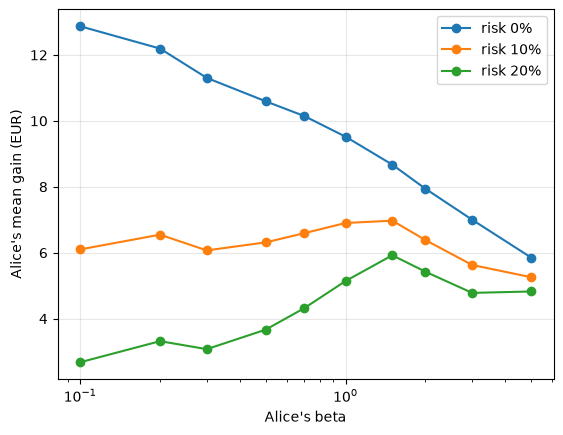

**Reading.**  
Without risk, the more Boulware the better.  
With a risk of breakdown, the best $\beta$ moves to about 1 to 1.5 (a slightly Conceder Alice): Alice must balance **what she gains by waiting** against **the risk of losing the deal**.

---

## Key points

| Strategy | Behaviour | Result |
|---|---|---|
| Boulware ($\beta < 1$) | firm, concedes at the last moment | wins more (like a patient agent) |
| Conceder ($\beta > 1$) | concedes early | leaves surplus, but deals more often |
| risk of breakdown | the talks may stop at each round | two Boulware agents often fail |